**과제 (강의자료 Ch5 p60, Homework)**
- Do Example 5.1: Blackjack → Solve Exercise 5.1 and 5.2
- Draw Figure 5.1, 5.2, 5.3
- Do Crab Bot
- Solve Exercise 5.4
- Do Example 5.5: Infinite Variance
- Draw Figure 5.4
- Solve Exercise 5.6, 5.7, 5.8

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)
rng = np.random.default_rng(0)

**Blackjack**(교재 p.93)

- 상태 = (플레이어 합 12–21, 딜러 공개 카드 1–10, usable ace 여부) 200개
- 행동: STICK=0, HIT=1
- 보상: 승 +1, 패 −1, 무 0 (γ = 1, 중간 보상 0)
- 플레이어 합이 11 이하면 무조건 hit이므로(질 수 없음) 12부터 상태로 본다.
- 딜러는 17 이상이면 stick.

In [2]:
STICK, HIT = 0, 1

def draw_card():
    return min(int(rng.integers(1, 14)), 10)      # J, Q, K = 10, A = 1

def add_card(total, usable_ace, card):
    # 카드 한 장을 더했을 때의 (합, usable ace)
    if card == 1 and total + 11 <= 21:
        total, usable_ace = total + 11, True
    else:
        total += card
    if total > 21 and usable_ace:                  # ace를 11 → 1로 바꿈
        total, usable_ace = total - 10, False
    return total, usable_ace

def dealer_plays(showing):
    total, ace = add_card(0, False, showing)
    total, ace = add_card(total, ace, draw_card())  # 숨긴 카드
    while total < 17:
        total, ace = add_card(total, ace, draw_card())
    return total

def random_start():
    # 플레이어 합이 12 이상이 될 때까지 카드를 받음
    total, ace = 0, False
    while total < 12:
        total, ace = add_card(total, ace, draw_card())
    return (total, draw_card(), ace)

def play_episode(policy, start_state=None, start_action=None):
    # policy(state) -> action.  반환: [(state, action), ...], 최종 보상
    state = start_state if start_state is not None else random_start()
    player, showing, ace = state
    trajectory = []
    action = start_action if start_action is not None else policy(state)
    while True:
        trajectory.append(((player, showing, ace), action))
        if action == STICK:
            break
        player, ace = add_card(player, ace, draw_card())
        if player > 21:
            return trajectory, -1.0                 # bust
        action = policy((player, showing, ace))
    dealer = dealer_plays(showing)
    if dealer > 21 or player > dealer:
        return trajectory, 1.0
    return trajectory, (0.0 if player == dealer else -1.0)

def idx(state):
    player, showing, ace = state
    return player - 12, showing - 1, int(ace)

def stick_20(state):
    return STICK if state[0] >= 20 else HIT         # Example 5.1의 고정 정책

**Figure 5.1**: First-visit MC prediction (교재 p.92 의사코드)
- 정책: 합이 20, 21이면 stick, 아니면 hit. 10,000 / 500,000 에피소드로 $v_\pi$를 추정한다.
- 동시에 every-visit 추정치도 같은 에피소드로 계산 (for Exercise 5.2)

In [3]:
def mc_prediction(policy, n_episodes):
    sum_first, cnt_first = np.zeros((10, 10, 2)), np.zeros((10, 10, 2))
    sum_every, cnt_every = np.zeros((10, 10, 2)), np.zeros((10, 10, 2))
    repeated_state_episodes = 0
    for _ in range(n_episodes):
        trajectory, G = play_episode(policy)      # 중간 보상 0, γ=1 → 모든 시점의 리턴 = 최종 보상
        seen = set()
        for state, _ in trajectory:
            i = idx(state)
            sum_every[i] += G; cnt_every[i] += 1
            if state in seen:
                repeated_state_episodes += 1
                continue
            seen.add(state)
            sum_first[i] += G; cnt_first[i] += 1
    v_first = np.divide(sum_first, cnt_first, out=np.zeros_like(sum_first), where=cnt_first > 0)
    v_every = np.divide(sum_every, cnt_every, out=np.zeros_like(sum_every), where=cnt_every > 0)
    return v_first, v_every, repeated_state_episodes

t0 = time.time()
v_10k, v_10k_every, rep_10k = mc_prediction(stick_20, 10_000)
v_500k, v_500k_every, rep_500k = mc_prediction(stick_20, 500_000)
print(f'done in {time.time()-t0:.1f}s')
print('Exercise 5.2 check -> repeated states inside an episode:', rep_10k + rep_500k)
print('max |first-visit - every-visit| (500k):', np.abs(v_500k - v_500k_every).max())

done in 3.9s
Exercise 5.2 check -> repeated states inside an episode: 0
max |first-visit - every-visit| (500k): 0.0


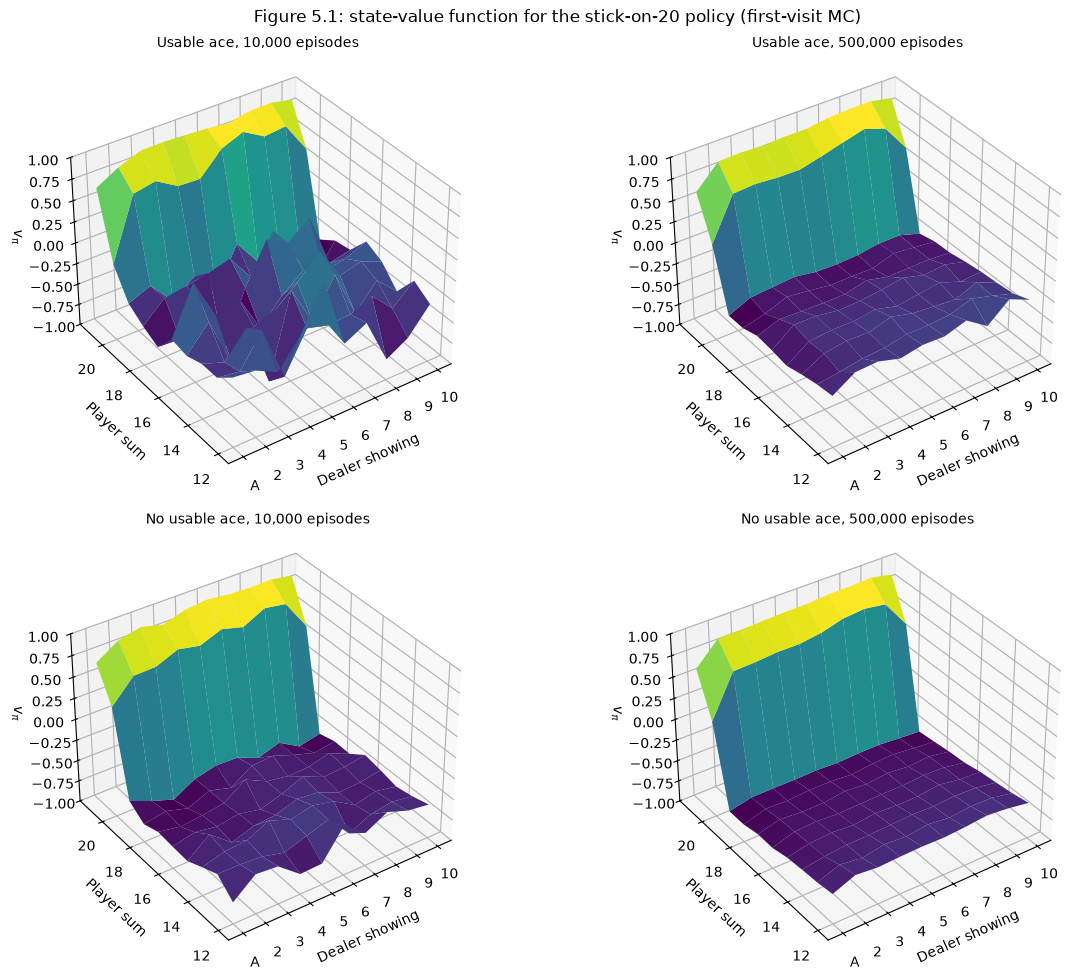

In [4]:
def surface(ax, Z, title, zlim=(-1, 1), zlabel=r'$v_\pi$'):
    X, Y = np.meshgrid(np.arange(1, 11), np.arange(12, 22))
    ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Dealer showing'); ax.set_ylabel('Player sum'); ax.set_zlabel(zlabel)
    ax.set_xticks(range(1, 11)); ax.set_xticklabels(['A'] + [str(k) for k in range(2, 11)])
    ax.set_zlim(*zlim); ax.view_init(elev=35, azim=-125)

fig = plt.figure(figsize=(13, 10))
for k, (V, n) in enumerate([(v_10k, '10,000'), (v_500k, '500,000')]):
    surface(fig.add_subplot(2, 2, 1 + k, projection='3d'), V[:, :, 1], f'Usable ace, {n} episodes')
    surface(fig.add_subplot(2, 2, 3 + k, projection='3d'), V[:, :, 0], f'No usable ace, {n} episodes')
fig.suptitle('Figure 5.1: state-value function for the stick-on-20 policy (first-visit MC)')
plt.tight_layout(); plt.savefig('figures/fig5_1_blackjack_prediction.png', dpi=130); plt.show()

**Exercise 5.1**

- 뒤쪽 두 줄에서 튀어 오르는 이유: 정책에 따르면 20, 21에서만 stick한다. 20–21로 멈추면 딜러가 이기기 매우 어려워서 승률이 높아 가치가 높다. 그외의(19 이하) 경우에서는 계속 hit해야 하므로 bust 위험이 커서 가치가 낮다.
- 맨 왼쪽 줄에서 떨어지는 이유: 딜러가 에이스를 보여주면 딜러가 21이나 높은 합을 만들기 쉬워서 플레이어가 불리해진다.
- 위 그림의 앞쪽 값이 더 높은 이유: usable ace가 있으면 hit해서 21을 넘어도 ace를 1로 바꿔 bust하지 않고 계속 진행할 수 있어서 bust 위험이 작으니 가치가 높다. 앞쪽은 hit을 여러 번 해야 하는 구간이라 값이 더 높다.

---

**Exercise 5.2**

같다고 생각한다. 블랙잭에서는 한 에피소드 안에서 같은 상태를 두 번 방문할 수 없어서 사실상 모든 방문이 첫 방문이다. 따라서 first-visit과 every-visit이 같은 리턴을 평균한다.

---

**Figure 5.2**: Monte Carlo ES (교재 p.99 의사코드)

- Exploring starts: 모든 (상태, 행동) 쌍의 시작 확률이 0보다 크도록 시작 상태 200개와 첫 행동 2개를 균등하게 무작위로 고른다.
- 초기 정책은 Example 5.1의 stick-on-20 정책, 100만 에피소드.
- `Returns` 리스트 대신 횟수 $N(s,a)$만 저장해서 점진적으로 평균을 낸다 (Exercise 5.4).

MC ES done in 9.2s


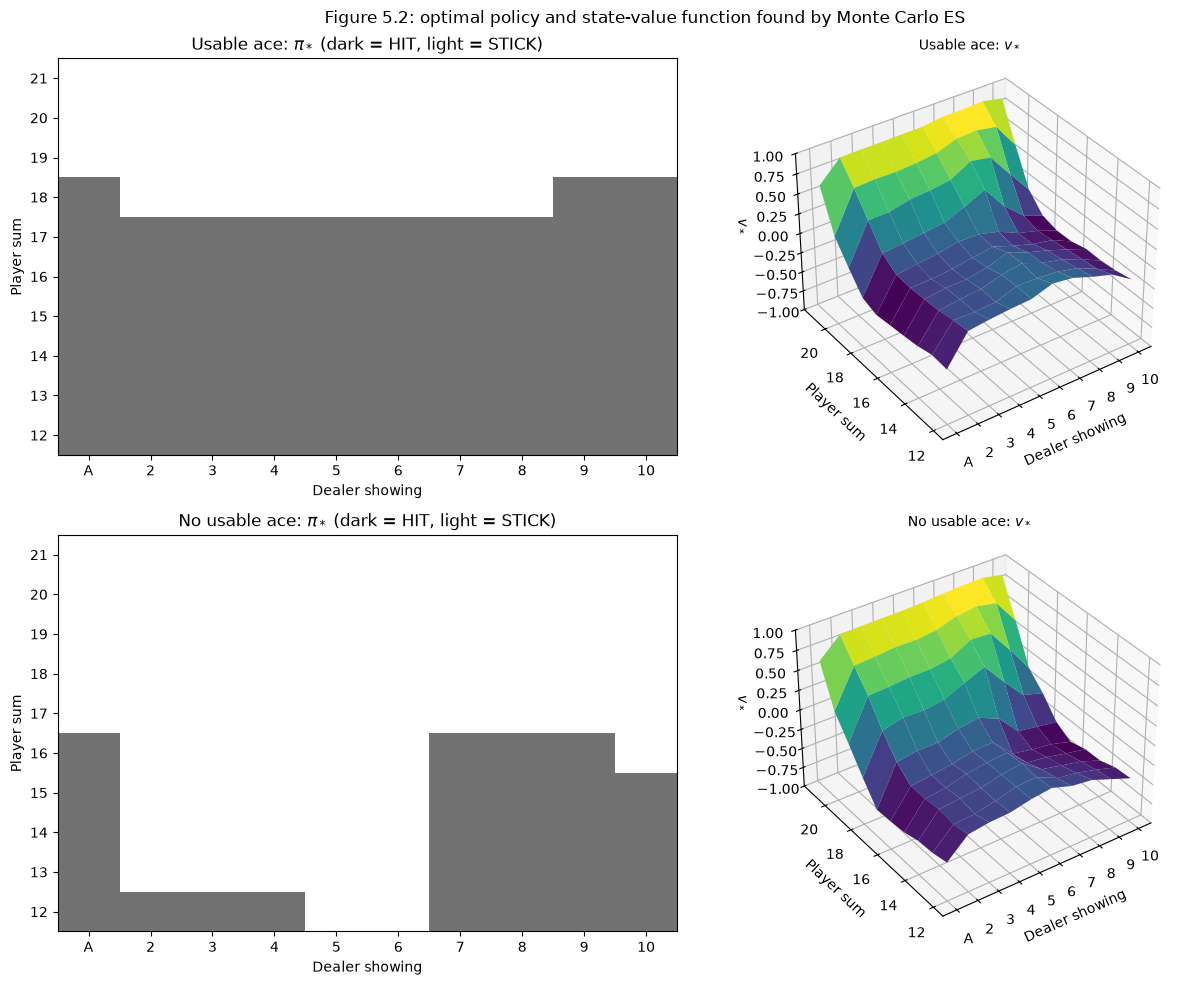

No usable ace: lowest sum where STICK, for each dealer card A..10:
[17, 13, 13, 13, 12, 12, 17, 17, 17, 16]


In [5]:
def mc_es(n_episodes):
    Q = np.zeros((10, 10, 2, 2))            # [player, dealer, ace, action]
    N = np.zeros((10, 10, 2, 2))
    policy = np.zeros((10, 10, 2), dtype=int)
    policy[:8] = HIT                         # 초기 정책: 20, 21에서만 stick
    greedy = lambda s: policy[idx(s)]
    for _ in range(n_episodes):
        start = (int(rng.integers(12, 22)), int(rng.integers(1, 11)), bool(rng.integers(2)))
        trajectory, G = play_episode(greedy, start, int(rng.integers(2)))
        for state, action in trajectory:     # 상태가 반복되지 않으므로 모든 방문이 첫 방문
            i = idx(state) + (action,)
            N[i] += 1
            Q[i] += (G - Q[i]) / N[i]        # Exercise 5.4: incremental update
            q = Q[idx(state)]
            policy[idx(state)] = HIT if q[HIT] > q[STICK] else STICK
    return Q, policy

t0 = time.time()
Q_es, pi_es = mc_es(1_000_000)
print(f'MC ES done in {time.time()-t0:.1f}s')
v_es = Q_es.max(axis=3)

fig = plt.figure(figsize=(13, 10))
for k, ace in enumerate([1, 0]):
    ax = fig.add_subplot(2, 2, 1 + 2 * k)
    ax.imshow(pi_es[:, :, ace], origin='lower', cmap='Greys', vmin=0, vmax=1.6,
              extent=[0.5, 10.5, 11.5, 21.5], aspect='auto')
    ax.set_xticks(range(1, 11)); ax.set_xticklabels(['A'] + [str(c) for c in range(2, 11)])
    ax.set_yticks(range(12, 22)); ax.set_xlabel('Dealer showing'); ax.set_ylabel('Player sum')
    ax.set_title(('Usable ace' if ace else 'No usable ace') + r': $\pi_*$ (dark = HIT, light = STICK)')
    surface(fig.add_subplot(2, 2, 2 + 2 * k, projection='3d'), v_es[:, :, ace],
            ('Usable ace' if ace else 'No usable ace') + r': $v_*$', zlabel=r'$v_*$')
fig.suptitle('Figure 5.2: optimal policy and state-value function found by Monte Carlo ES')
plt.tight_layout(); plt.savefig('figures/fig5_2_mc_es.png', dpi=130); plt.show()

print('No usable ace: lowest sum where STICK, for each dealer card A..10:')
print([int(12 + np.argmax(pi_es[:, d, 0] == STICK)) if (pi_es[:, d, 0] == STICK).any() else None for d in range(10)])

**Figure 5.3**: Off-policy 예측, Ordinary vs Weighted IS (Example 5.4, 교재 p.106)

- 시작 상태: 딜러 2, 플레이어 합 13, usable ace / 참값 $v_\pi(s)\approx-0.27726$
- 목표 정책 π: 20, 21에서 stick / 행동 정책 b: hit, stick 반반
- π가 결정적이라 행동이 π와 같으면 비율 $1/0.5=2$, 다르면 0
$$V_{ordinary}=\frac{\sum\rho G}{n},\qquad V_{weighted}=\frac{\sum\rho G}{\sum\rho}$$
- 100 run 평균 MSE 비교

done in 6.1s
episodes=     1: MSE ordinary=15.6285, weighted=0.1858
episodes=    10: MSE ordinary=0.9439, weighted=0.5004
episodes=   100: MSE ordinary=0.1059, weighted=0.1064
episodes=  1000: MSE ordinary=0.0094, weighted=0.0084
episodes= 10000: MSE ordinary=0.0007, weighted=0.0006


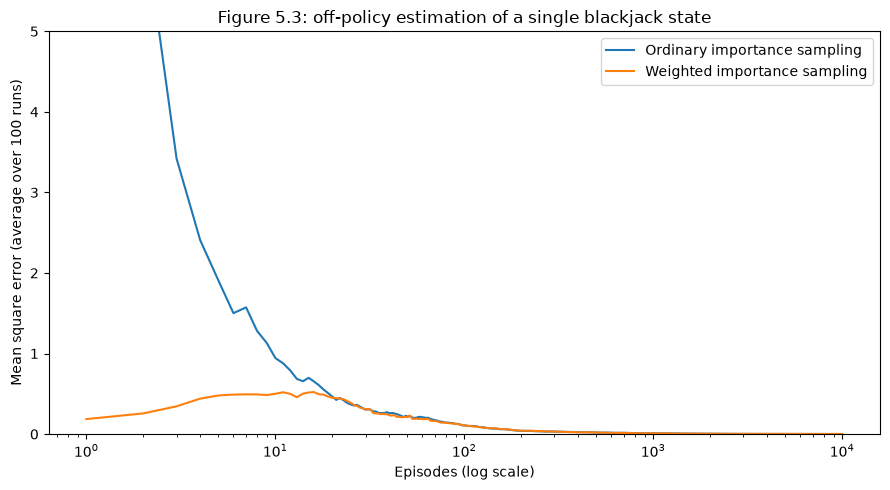

In [7]:
START_STATE = (13, 2, True)
TRUE_VALUE = -0.27726
random_policy = lambda s: int(rng.integers(2))

def off_policy_mse(n_episodes=10_000, n_runs=100):
    err_ord = np.zeros(n_episodes); err_w = np.zeros(n_episodes)
    for _ in range(n_runs):
        rho_G = np.zeros(n_episodes); rho = np.zeros(n_episodes)
        for e in range(n_episodes):
            trajectory, G = play_episode(random_policy, START_STATE)
            r = 1.0
            for state, action in trajectory:
                r = r * 2.0 if action == stick_20(state) else 0.0
                if r == 0.0:
                    break
            rho[e], rho_G[e] = r, r * G
        num, den = np.cumsum(rho_G), np.cumsum(rho)
        ordinary = num / np.arange(1, n_episodes + 1)
        weighted = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
        err_ord += (ordinary - TRUE_VALUE) ** 2
        err_w += (weighted - TRUE_VALUE) ** 2
    return err_ord / n_runs, err_w / n_runs

t0 = time.time()
mse_ord, mse_w = off_policy_mse()
print(f'done in {time.time()-t0:.1f}s')
for n in [1, 10, 100, 1000, 10000]:
    print(f'episodes={n:6d}: MSE ordinary={mse_ord[n-1]:.4f}, weighted={mse_w[n-1]:.4f}')

plt.figure(figsize=(9, 5))
x = np.arange(1, len(mse_ord) + 1)
plt.plot(x, mse_ord, label='Ordinary importance sampling')
plt.plot(x, mse_w, label='Weighted importance sampling')
plt.xscale('log'); plt.ylim(0, 5); plt.xlabel('Episodes (log scale)')
plt.ylabel('Mean square error (average over 100 runs)')
plt.title('Figure 5.3: off-policy estimation of a single blackjack state')
plt.legend(); plt.tight_layout(); plt.savefig('figures/fig5_3_off_policy.png', dpi=130); plt.show()

**Crab Bot** (강의자료 Ch5 p15–17)

- 상태 s1–s7, 행동 TryLeft / TryRight, $\mathcal R=[1\ 0\ 0\ 0\ 0\ 0\ 10]$ (어떤 행동이든)
- $\pi(s)$ = TryLeft for all s, $\gamma=1$, s1과 s7에서의 행동은 에피소드를 종료한다.
- 궤적: ($s_4$, TryLeft, 0, $s_3$, TryLeft, 0, $s_3$, TryLeft, 0, $s_2$, TryLeft, 0, $s_1$, TryLeft, 1, T)
- 문제: 각 상태의 first-visit MC 추정값, $s_3$의 every-visit MC 추정값

In [9]:
trajectory = [('s4', 0), ('s3', 0), ('s3', 0), ('s2', 0), ('s1', 1)]   # (상태, 그 상태에서 받은 보상)
G, returns = 0.0, []
for s, r in reversed(trajectory):          # 뒤에서부터 G <- gamma*G + R  (gamma = 1)
    G = 1.0 * G + r
    returns.append((s, G))
returns.reverse()
print('returns per visit:', returns)

first, every = {}, {}
for s, g in returns:
    every.setdefault(s, []).append(g)
    if s not in first:
        first[s] = g
print('first-visit MC V:', {s: first[s] for s in sorted(first)}, '(s5~s7: not visited)')
print('every-visit MC V(s3):', np.mean(every['s3']), '<- returns of s3:', every['s3'])

returns per visit: [('s4', 1.0), ('s3', 1.0), ('s3', 1.0), ('s2', 1.0), ('s1', 1.0)]
first-visit MC V: {'s1': 1.0, 's2': 1.0, 's3': 1.0, 's4': 1.0} (s5~s7: not visited)
every-visit MC V(s3): 1.0 <- returns of s3: [1.0, 1.0]


**Exercise 5.4**

Returns(s,a) 리스트를 없애고 방문 횟수 $N(s,a)$만 저장한다. 의사코드의 마지막 부분을 다음처럼 바꾼다.

- 초기화: $N(s,a)\leftarrow0$ for all $s, a$
- `Append G to Returns(S_t, A_t)`, `Q(S_t, A_t) ← average(Returns(S_t, A_t))` 대신
$$N(S_t,A_t)\leftarrow N(S_t,A_t)+1,\qquad Q(S_t,A_t)\leftarrow Q(S_t,A_t)+\frac{1}{N(S_t,A_t)}\big[G-Q(S_t,A_t)\big]$$


---

**Example 5.5: Infinite Variance** (교재 p.106)

- 비종료 상태 s 하나, 행동 left / right
- right: 바로 종료, 보상 0 / left: 0.9 확률로 s로 돌아오고 0.1 확률로 종료, 보상 +1
- 목표 정책 π: 항상 left → $v_\pi(s)=1$ / 행동 정책 b: 반반

구현 방법: b를 따르면 매 스텝 right(0.5) → 종료, left & 종료(0.05) → 종료, left & 계속(0.45)이라 에피소드 길이가 종료 확률 0.55인 기하분포를 따른다. 그래서 numpy로 한 번에 샘플링

done in 0.7s
final ordinary-IS estimates (10 runs): [0.773 0.762 0.791 1.102 0.773 0.786 0.753 0.839 0.796 0.836]
final weighted-IS estimates (10 runs): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


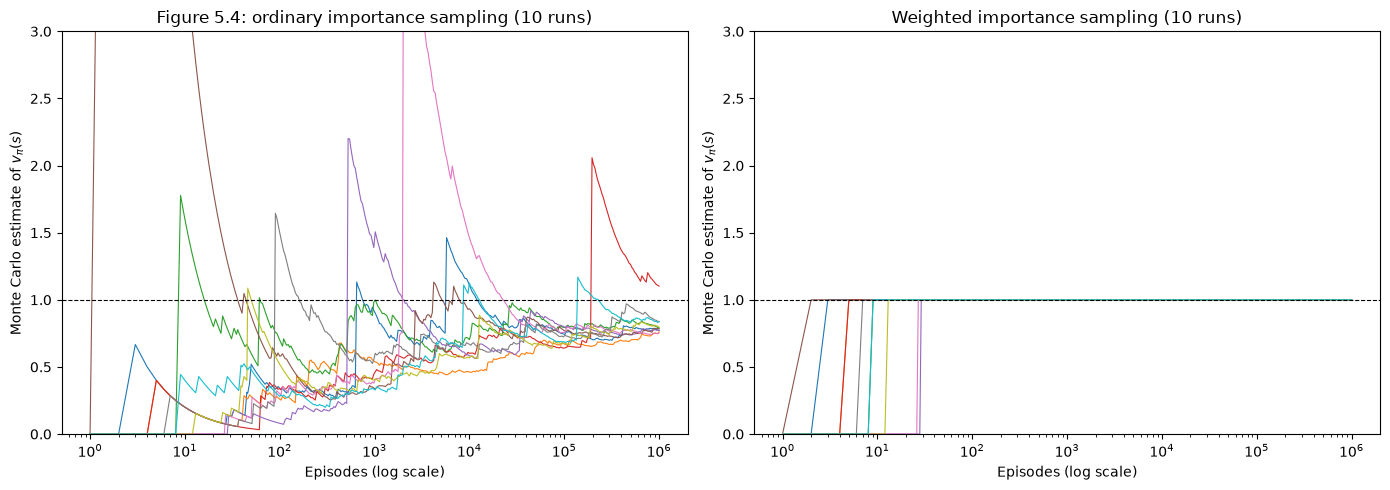

In [10]:
def infinite_variance_runs(n_episodes=1_000_000, n_runs=10, seed=1):
    g = np.random.default_rng(seed)
    curves_ord, curves_w = [], []
    for _ in range(n_runs):
        k = g.geometric(0.55, n_episodes)                    # 에피소드 길이(스텝 수)
        ended_left = g.random(n_episodes) < (0.05 / 0.55)    # 마지막 스텝이 left & 종료였는가
        rho = np.where(ended_left, 2.0 ** k, 0.0)            # 모든 행동이 left일 때만 비율 = 2^k
        rho_G = rho * 1.0                                    # left로 끝나면 G = 1, 아니면 rho = 0
        n = np.arange(1, n_episodes + 1)
        num, den = np.cumsum(rho_G), np.cumsum(rho)
        curves_ord.append(num / n)
        curves_w.append(np.divide(num, den, out=np.zeros_like(num), where=den > 0))
    return np.array(curves_ord), np.array(curves_w)

t0 = time.time()
ord_curves, w_curves = infinite_variance_runs()
print(f'done in {time.time()-t0:.1f}s')
print('final ordinary-IS estimates (10 runs):', np.round(ord_curves[:, -1], 3))
print('final weighted-IS estimates (10 runs):', np.round(w_curves[:, -1], 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(1, ord_curves.shape[1] + 1)
sel = np.unique(np.logspace(0, 6, 400).astype(int)) - 1
for c in ord_curves:
    axes[0].plot(x[sel], c[sel], lw=0.8)
axes[0].set_title('Figure 5.4: ordinary importance sampling (10 runs)')
for c in w_curves:
    axes[1].plot(x[sel], c[sel], lw=0.8)
axes[1].set_title('Weighted importance sampling (10 runs)')
for ax in axes:
    ax.axhline(1.0, color='k', ls='--', lw=0.8); ax.set_xscale('log'); ax.set_ylim(0, 3)
    ax.set_xlabel('Episodes (log scale)'); ax.set_ylabel(r'Monte Carlo estimate of $v_\pi(s)$')
plt.tight_layout(); plt.savefig('figures/fig5_4_infinite_variance.png', dpi=130); plt.show()

**Exercise 5.6**: What is the equation analogous to (5.6) for action values $Q(s,a)$ instead of state values $V(s)$, again given returns generated using $b$?

$\mathcal T(s,a)$를 (s,a)를 방문한 시각들의 집합이라 하면
$$Q(s,a)\doteq\frac{\sum_{t\in\mathcal T(s,a)}\rho_{t+1:T(t)-1}\,G_t}{\sum_{t\in\mathcal T(s,a)}\rho_{t+1:T(t)-1}}$$

비율이 $t$가 아니라 $t+1$부터 시작한다. $Q(s,a)$는 행동 $a$를 이미 했다는 조건이 붙은 가치라서 첫 행동 $A_t=a$의 확률은 보정할 필요가 없기 때문이다.

---

**Exercise 5.7**: In learning curves such as those shown in Figure 5.3 error generally decreases with training, as indeed happened for the ordinary importance-sampling method. But for the weighted importance-sampling method error first increased and then decreased. Why do you think this happened?

weighted IS는 $\rho=0$인 에피소드가 나오면 추정치가 변하지 않는다. 그래서 비율이 0이 아닌 첫 에피소드가 나오기 전까지는 추정치가 초기값 0이고, 오차가 $(0+0.277)^2\approx0.077$로 작다. 그런데 비율이 0이 아닌 첫 에피소드가 나오면 추정치가 그 에피소드의 리턴(±1 또는 0) 그대로가 되어 오차가 $(1+0.277)^2\approx1.6$처럼 튀어 오른다. 그 뒤로 표본이 쌓이면서 평균이 참값에 가까워져 오차가 줄어든다. 즉 초기값 0이 우연히 참값에 가까웠다가, 적은 표본에 휘둘리는 구간을 거쳐 수렴하는 것이다.

---

**Exercise 5.8**: The results with Example 5.5 and shown in Figure 5.4 used a first-visit MC method. Suppose that instead an every-visit MC method was used on the same problem. Would the variance of the estimator still be infinite? Why or why not?

여전히 무한일 것이다. first-visit에서도 이미
$$\mathbb E_b[(\rho G)^2]=\sum_{k=0}^{\infty}(0.45)^k(0.05)\,(2^{k+1})^2=0.2\sum_{k=0}^{\infty}1.8^k=\infty$$
로 발산한다. every-visit은 길이 $k$인 에피소드에서 s의 모든 방문에 대해 $2^{k},2^{k-1},\dots$인 항을 모두 쓰는데, 이 합은 first-visit의 항 $2^k$보다 작지 않다. 그래서 제곱의 기댓값도 발산한다. 